# ANALISIS EXPLORARIO DE DATOS (EDA)


### LIBRERIAS IMPORTADAS: pandas, numpy, matplotlib y seaborn.


In [22]:
# Importamos las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargamos el set de datos
df = pd.read_csv('/home/ray/proyectos/satisfaccion-aerolinea/data/airline_passenger_satisfaction.csv')

# definimos las decimales a mostrar
pd.set_option("display.float_format", "{:.2f}".format)

In [23]:
display(df.shape)

(103904, 25)

In [24]:
display(df.head(16))

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.00,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.00,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.00,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.00,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.00,satisfied
5,5,111157,Female,Loyal Customer,26,Personal Travel,Eco,1180,3,4,...,1,3,4,4,4,4,1,0,0.00,neutral or dissatisfied
6,6,82113,Male,Loyal Customer,47,Personal Travel,Eco,1276,2,4,...,2,3,3,4,3,5,2,9,23.00,neutral or dissatisfied
7,7,96462,Female,Loyal Customer,52,Business travel,Business,2035,4,3,...,5,5,5,5,4,5,4,4,0.00,satisfied
8,8,79485,Female,Loyal Customer,41,Business travel,Business,853,1,2,...,1,1,2,1,4,1,2,0,0.00,neutral or dissatisfied
9,9,65725,Male,disloyal Customer,20,Business travel,Eco,1061,3,3,...,2,2,3,4,4,3,2,0,0.00,neutral or dissatisfied


In [25]:
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  str    
 3   Customer Type                      103904 non-null  str    
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  str    
 6   Class                              103904 non-null  str    
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      103904 non-null

None

In [26]:
display(df.isna().sum()[df.isna().sum() > 0])

Arrival Delay in Minutes    310
dtype: int64

### Análisis y tratamiento de valores nulos: `Arrival Delay in Minutes`

Durante la revisión inicial del conjunto de datos facilitado por **Iberia**, se ha detectado que `Arrival Delay in Minutes` es la **única columna con valores ausentes** (**310 registros**, menos del 0,3 % del total). Con el objetivo de **conservar el 100 % de los pasajeros** en el análisis y evitar sesgos antes de la fase de modelado, se evalúa la estrategia de imputación más rigurosa:

- **Descarte de imputación simple con `0`:** asumiría que todos los vuelos sin registro llegaron puntuales, incluso si salieron con un retraso considerable.
- **Descarte de imputación con la media global:** la distribución de retrasos presenta una fuerte asimetría positiva (valores extremos muy altos), por lo que la media sobrestimaría el retraso habitual.
- **Hipótesis propuesta (imputación basada en dominio):** utilizar el valor de `Departure Delay in Minutes` del mismo vuelo como estimación del retraso en llegada.

#### Validación empírica sobre registros completos
Antes de aplicar esta regla, validamos su precisión comparando ambas variables en los vuelos con datos completos:
1. **Correlación (`Departure` vs. `Arrival`):** `[valor de .corr()]`
2. **Error absoluto medio (`MAE`) y mediana de la diferencia `|Arrival - Departure|`:** `[media]` min / `[mediana]` min *(frente a `[media de Arrival]` min si imputáramos con `0`)*.
3. **Verificación visual:** el diagrama de dispersión confirma si la relación es lineal y suficientemente estable como para aceptar esta regla en el *pipeline* de preprocesamiento para **Iberia**.

In [27]:
diff = (df["Arrival Delay in Minutes"] - df["Departure Delay in Minutes"]).abs()
diff.describe()

count   103594.00
mean         4.97
std          8.81
min          0.00
25%          0.00
50%          1.00
75%          7.00
max        234.00
dtype: float64

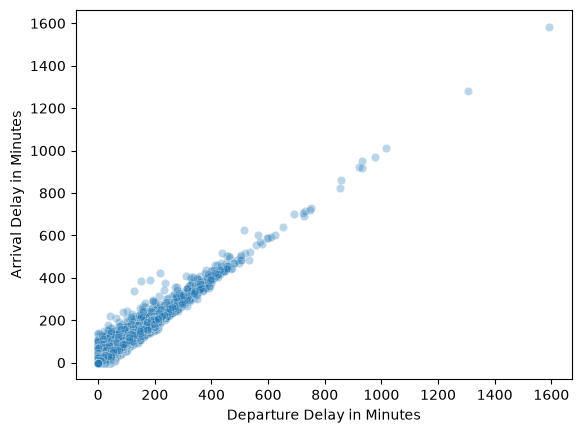

In [29]:
sns.scatterplot(data=df, x="Departure Delay in Minutes", y="Arrival Delay in Minutes", alpha=0.3)
plt.show()

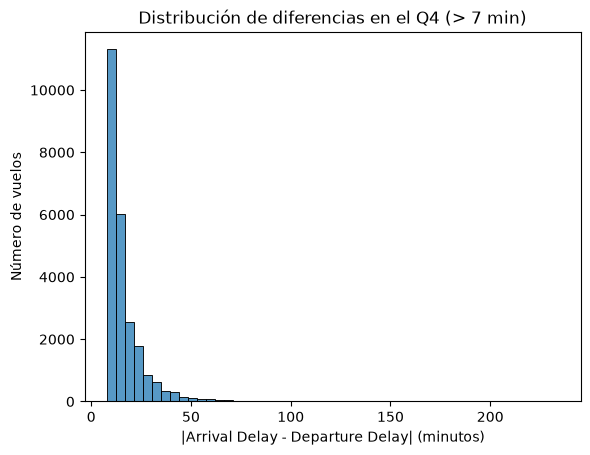

In [30]:
q4_diff = diff[diff > 7]

sns.histplot(q4_diff, bins=50)
plt.title("Distribución de diferencias en el Q4 (> 7 min)")
plt.xlabel("|Arrival Delay - Departure Delay| (minutos)")
plt.ylabel("Número de vuelos")
plt.show()

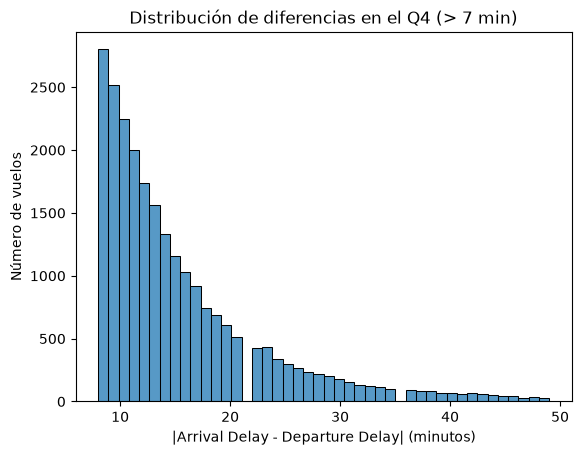

In [35]:
q4_diff = diff[(diff > 7) & (diff < 50)]

sns.histplot(q4_diff, bins=44)
plt.title("Distribución de diferencias en el Q4 (> 7 min)")
plt.xlabel("|Arrival Delay - Departure Delay| (minutos)")
plt.ylabel("Número de vuelos")
plt.show()

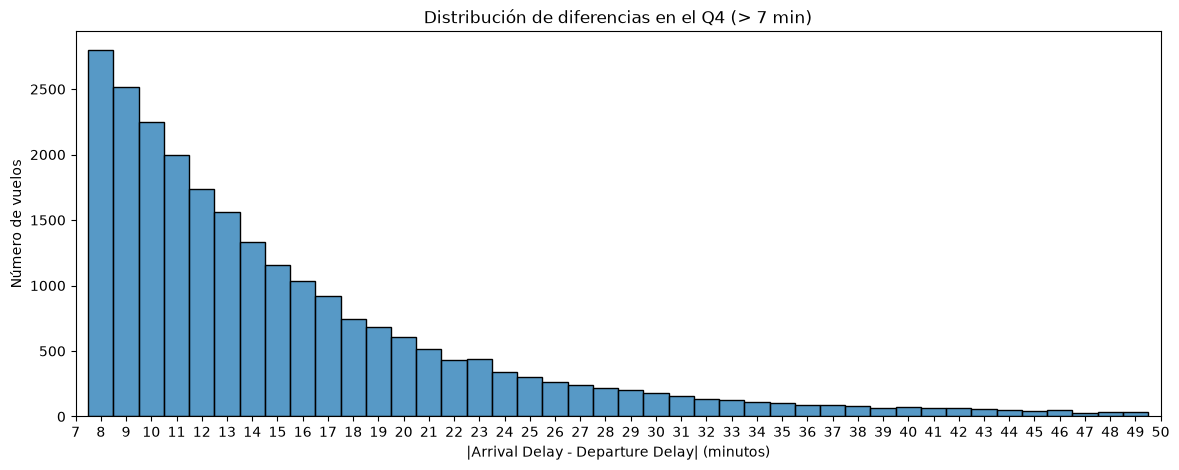

In [37]:
# Repasar esto porque se ha peidido a Antigravity que haga el grafico mas bonito y que se vea mejor.

plt.figure(figsize=(14, 5))          # wider chart so 1-minute labels don't overlap
sns.histplot(q4_diff, discrete=True) # 1 exact bar per integer minute (fixes the gaps!)
plt.xlim(7, 50)                      # start x-axis at 7 (adjust 50 to your upper cutoff)
plt.xticks(range(7, 51, 1))          # tick marks every 1 minute from 7 to 50
plt.title("Distribución de diferencias en el Q4 (> 7 min)")
plt.xlabel("|Arrival Delay - Departure Delay| (minutos)")
plt.ylabel("Número de vuelos")
plt.show()

#### Decisión de imputación (`Arrival Delay in Minutes`)
Los datos completos (103.594 vuelos) confirman que `Departure Delay in Minutes` es un excelente estimador de `Arrival Delay in Minutes`:
- El **50 %** de los vuelos presenta una diferencia de **≤ 1 minuto** y el **75 %** de **≤ 7 minutos** (error absoluto medio de **4,97 min**).
- En el **Q4 (> 7 min)** la frecuencia cae de forma pronunciada minuto a minuto, confirmando que las discrepancias grandes son muy poco frecuentes.

**Conclusión:** Se aprueba imputar los **310 valores nulos** (< 0,3 % del dataset de **Iberia**) asignándoles el valor de `Departure Delay in Minutes` del mismo vuelo, preservando el 100 % de los registros sin introducir sesgos relevantes.

In [38]:
df["Arrival Delay in Minutes"] = df["Arrival Delay in Minutes"].fillna(df["Departure Delay in Minutes"])
df["Arrival Delay in Minutes"].isna().sum()

np.int64(0)

#### Análisis de valores atípicos (*outliers*) en `Arrival Delay in Minutes`
Se observan retrasos extremos que superan las 3 horas (`[N > 180]` vuelos) e incluso las 6 horas (`[N > 360]` vuelos), llegando hasta ~26 horas (~1.584 min).

- **¿Error de registro o evento real?** La coherencia entre `Departure Delay in Minutes` y `Arrival Delay in Minutes` en estos registros extremos indica que se trata de **retrasos operativos reales** (p. ej., incidencias técnicas o meteorológicas) y no de errores tipográficos.
- **Decisión para el EDA y modelado:**
  - **No se eliminan** los registros, ya que representan experiencias reales de pasajeros de **Iberia** con alto impacto potencial sobre la satisfacción.
  - En la fase de preprocesamiento (`02_modelado.ipynb` / `src/preprocess.py`), los modelos basados en árboles los gestionan sin problema, mientras que para modelos sensibles a la escala (como redes neuronales en **Keras** o regresión logística) se evaluará aplicar una transformación logarítmica (`log1p`) y escalado.

In [39]:
df.nlargest(10, "Arrival Delay in Minutes")[
    ["Departure Delay in Minutes", "Arrival Delay in Minutes", "Class", "satisfaction"]
]

,Departure Delay in Minutes,Arrival Delay in Minutes,Class,satisfaction
83741,1592,1584.00,Eco,neutral or dissatisfied
6744,1305,1280.00,Business,satisfied
61310,1017,1011.00,Business,satisfied
72206,978,970.00,Eco,neutral or dissatisfied
61287,930,952.00,Business,neutral or dissatisfied
61528,921,924.00,Business,neutral or dissatisfied
80182,933,920.00,Business,satisfied
27732,859,860.00,Business,satisfied
51860,853,823.00,Business,neutral or dissatisfied
37096,750,729.00,Eco,satisfied


#### Hallazgo inesperado en retrasos extremos: nuevas hipótesis a validar
Al inspeccionar los **10 vuelos con mayor retraso en llegada** (entre 12 y 26 horas), sorprende observar que **5 de los 10 pasajeros se declararon `satisfied`** (4 de ellos en clase `Business`). Esto sugiere que el retraso absoluto, por sí solo, no explica completamente la insatisfacción del cliente.

A raíz de este hallazgo, ampliamos el análisis con tres nuevas métricas para entender qué factores compensan o agravan un retraso:
1. **Distribución de la variable objetivo (`satisfaction`):** conocer sus categorías exactas y si el conjunto de datos de **Iberia** está balanceado.
2. **Variación del retraso en vuelo (`delay_diff = Arrival Delay - Departure Delay`):** evaluar si recuperar tiempo en el aire (valor negativo) frente a perder aún más tiempo (valor positivo) influye en la satisfacción del pasajero.
3. **Satisfacción según la clase (`Class`):** comprobar si viajar en `Business` amortigua la percepción negativa frente a `Eco` / `Eco Plus`.

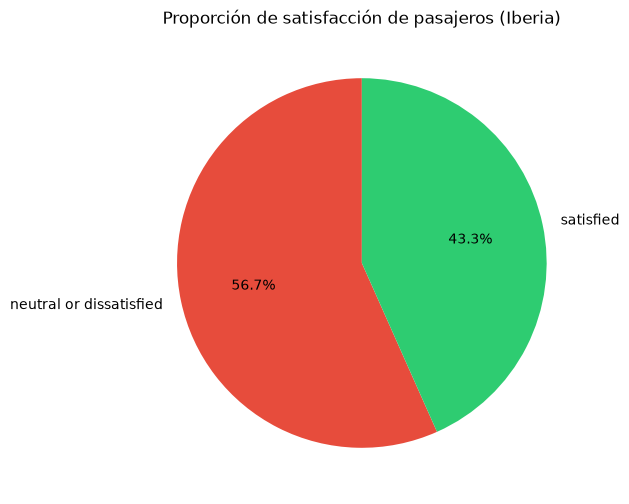

In [43]:
counts = df["satisfaction"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    counts,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#E74C3C", "#2ECC71"]
)
plt.title("Proporción de satisfacción de pasajeros (Iberia)")
plt.show()

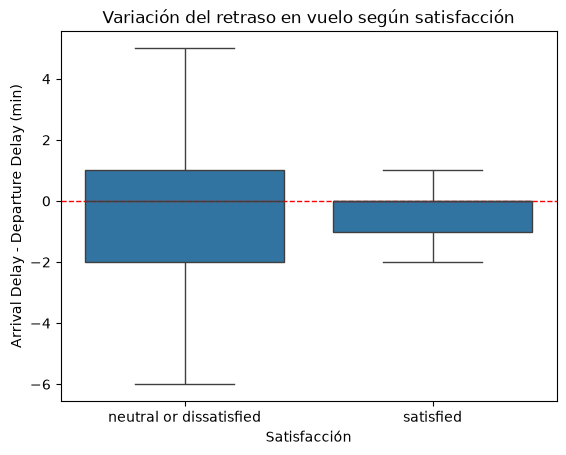

In [41]:
df["delay_diff"] = df["Arrival Delay in Minutes"] - df["Departure Delay in Minutes"]

sns.boxplot(data=df, x="satisfaction", y="delay_diff", showfliers=False)
plt.axhline(0, color="red", linestyle="--", linewidth=1)  # 0 = mismo retraso en salida y llegada
plt.title("Variación del retraso en vuelo según satisfacción")
plt.xlabel("Satisfacción")
plt.ylabel("Arrival Delay - Departure Delay (min)")
plt.show()

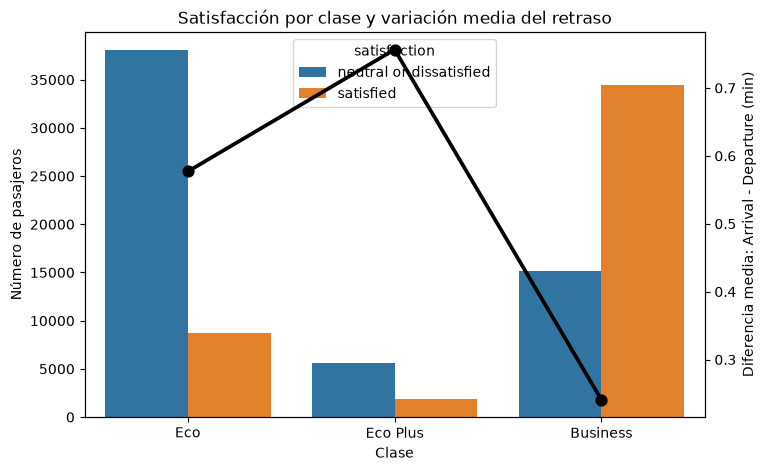

In [44]:
class_order = ["Eco", "Eco Plus", "Business"]

fig, ax1 = plt.subplots(figsize=(8, 5))

# Left y-axis: grouped bars
sns.countplot(data=df, x="Class", hue="satisfaction", order=class_order, ax=ax1)
ax1.set_xlabel("Clase")
ax1.set_ylabel("Número de pasajeros")

# Right y-axis: overlay line of mean delay_diff per class
ax2 = ax1.twinx()
sns.pointplot(
    data=df, x="Class", y="delay_diff",
    order=class_order, color="black", errorbar=None, ax=ax2
)
ax2.set_ylabel("Diferencia media: Arrival - Departure (min)")

plt.title("Satisfacción por clase y variación media del retraso")
plt.show()